# DSCI 552, Homework 2

Name: Ivan Sun  
GitHub Username: peterlololsss

## 1. Combined Cycle Power Plant Data Set

### (a) Download Data

Package imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

Get the Cycle Power Plant Data Set

In [2]:
df = pd.read_excel("../data/CCPP/Folds5x2_pp.xlsx", sheet_name="Sheet1")
df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


### (b) Exploring the data

#### i. rows and columns

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 9568
Columns: 5


9568 rows and 5 columns. Each row is one hour of the plant running at full load. The columns are temperature (AT), exhaust vacuum (V), ambient pressure (AP), relative humidity (RH) and energy output (PE). PE is the response and the other four are the predictors.

#### ii. pairwise scatterplots of all the varianbles

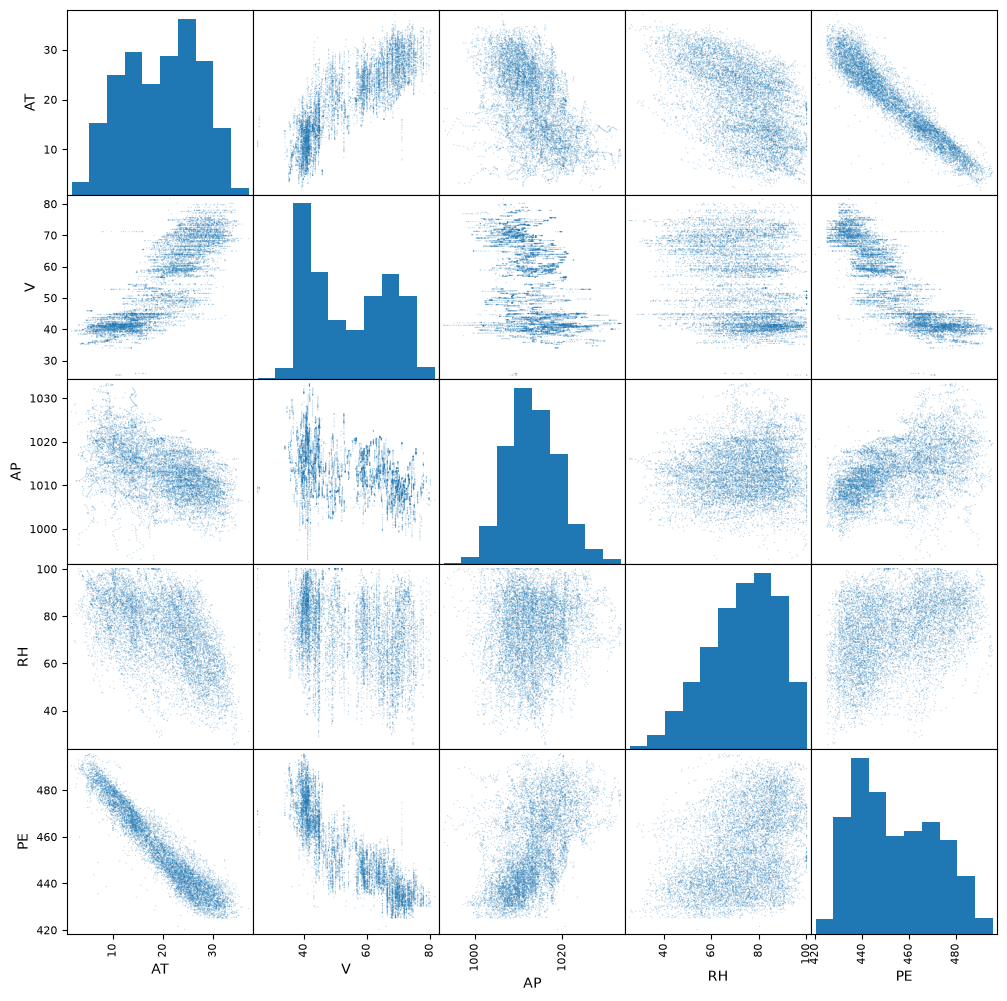

In [4]:
pd.plotting.scatter_matrix(df, figsize=(12, 12), s=3, alpha=0.3)
plt.show()

PE goes down as AT goes up, almost in a straight line. PE also goes down as V goes up. AP and RH have a weak positive relationship with PE. AT and V are also strongly correlated with each other.

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

In [5]:
summary = pd.DataFrame({
    "mean": df.mean(),
    "median": df.median(),
    "range": df.max() - df.min(),
    "Q1": df.quantile(0.25),
    "Q3": df.quantile(0.75),
})
summary["IQR"] = summary["Q3"] - summary["Q1"]
summary.round(2)

,mean,median,range,Q1,Q3,IQR
AT,19.65,20.34,35.30,13.51,25.72,12.21
V,54.31,52.08,56.20,41.74,66.54,24.80
AP,1013.26,1012.94,40.41,1009.10,1017.26,8.16
RH,73.31,74.97,74.60,63.33,84.83,21.50
PE,454.37,451.55,75.50,439.75,468.43,28.68


### (c) Simple Linear Regression

AT coef: -2.1713 p-value: 0.0 R^2: 0.8989
   outliers (|residual| > 3 std): 42
V coef: -1.1681 p-value: 0.0 R^2: 0.7565
   outliers (|residual| > 3 std): 33
AP coef: 1.4899 p-value: 0.0 R^2: 0.2688
   outliers (|residual| > 3 std): 28
RH coef: 0.4557 p-value: 0.0 R^2: 0.1519
   outliers (|residual| > 3 std): 2


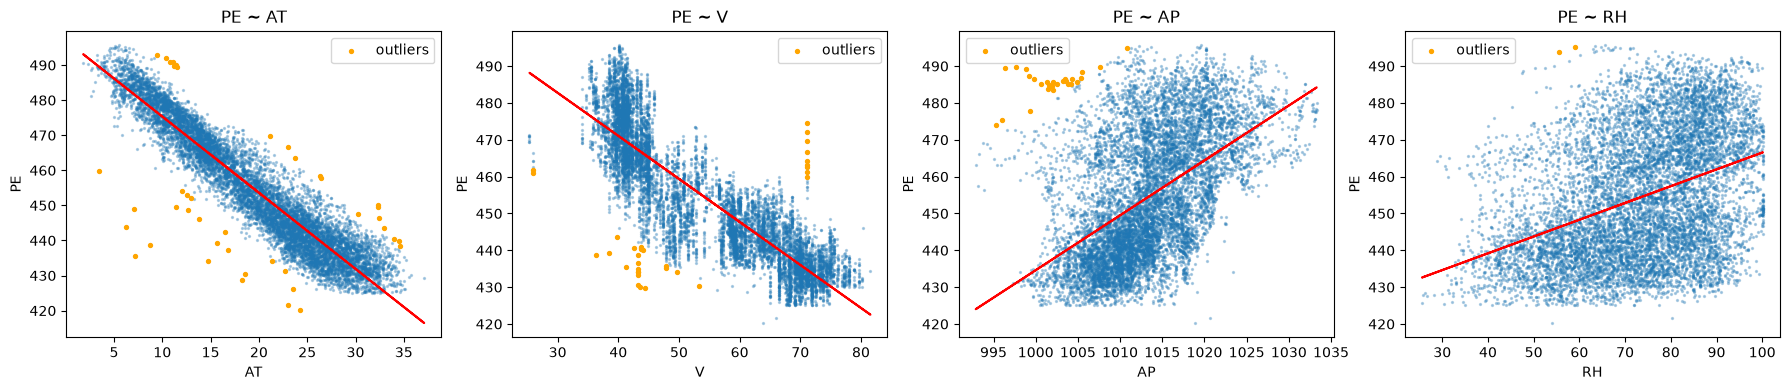

In [6]:
predictors = ["AT", "V", "AP", "RH"]
simple_coefs = []

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, p in enumerate(predictors):
    model = smf.ols("PE ~ " + p, data=df).fit()
    simple_coefs.append(model.params[p])
    outliers = abs(model.resid) > 3 * model.resid.std()

    print(p, "coef:", round(model.params[p], 4), "p-value:", model.pvalues[p], "R^2:", round(model.rsquared, 4))
    print("   outliers (|residual| > 3 std):", outliers.sum())

    axes[i].scatter(df[p], df["PE"], s=2, alpha=0.3)
    axes[i].scatter(df[p][outliers], df["PE"][outliers], s=8, color="orange", label="outliers")
    axes[i].plot(df[p], model.fittedvalues, color="red")
    axes[i].set_xlabel(p)
    axes[i].set_ylabel("PE")
    axes[i].set_title("PE ~ " + p)
    axes[i].legend()
plt.tight_layout()
plt.show()

All four predictors are significant (p-values are about 0). AT fits best ($R^2$ = 0.90), then V (0.76), AP (0.27) and RH (0.15). In the plots AT and V follow the line closely, and AP and RH are very spread out.

There are some outliers: 42 for AT, 33 for V, 28 for AP and 2 for RH (residual more than 3 std away, orange in the plots). I would remove the ones in the AT and V models, since they are clearly away from the rest of the points. For AP and RH the fit is already loose, so I would keep them.

### (d) Multiple Regression

In [7]:
model_all = smf.ols("PE ~ AT + V + AP + RH", data=df).fit()
print(model_all.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        22:59:35   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    454.6093      9.749     46.634      0.0

$R^2$ = 0.929. AT has the biggest effect: PE drops about 1.98 for every 1 degree of AT. All four p-values are below 0.05, so we can reject $H_0 : \beta_j = 0$ for AT, V, AP and RH.

### (e) 1c Compare to 1d

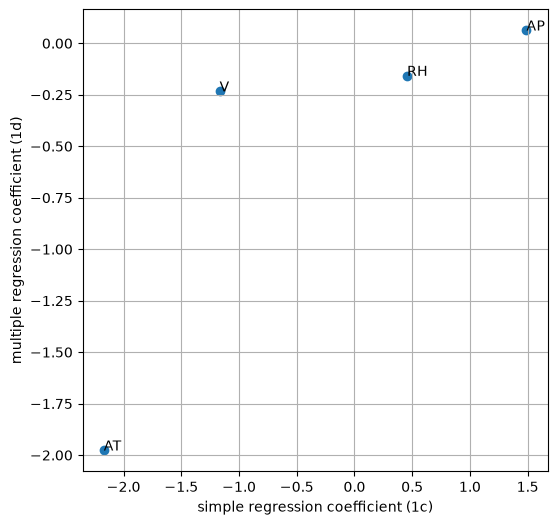

In [8]:
multiple_coefs = [model_all.params[p] for p in predictors]

plt.figure(figsize=(6, 6))
plt.scatter(simple_coefs, multiple_coefs)
for i, p in enumerate(predictors):
    plt.annotate(p, (simple_coefs[i], multiple_coefs[i]))
plt.xlabel("simple regression coefficient (1c)")
plt.ylabel("multiple regression coefficient (1d)")
plt.grid(True)
plt.show()

The AT coefficient is almost the same in both (-2.17 and -1.98). The other three get much closer to 0 in the multiple regression, and RH even changes sign (0.46 to -0.16). V, AP and RH are correlated with AT, so in the simple regressions they were partly picking up the effect of AT.

### (f) Nonlinear Association

In [9]:
for p in predictors:
    data = pd.DataFrame({"x": df[p] - df[p].mean(), "PE": df["PE"]})
    model = smf.ols("PE ~ x + I(x**2) + I(x**3)", data=data).fit()
    print(p, " p-value x^2 =", round(model.pvalues["I(x ** 2)"], 5),
          " p-value x^3 =", round(model.pvalues["I(x ** 3)"], 5), " R^2 =", round(model.rsquared, 4))

AT  p-value x^2 = 0.0  p-value x^3 = 0.0  R^2 = 0.9119
V  p-value x^2 = 0.0  p-value x^3 = 0.01373  R^2 = 0.775
AP  p-value x^2 = 0.0  p-value x^3 = 0.0  R^2 = 0.2975
RH  p-value x^2 = 0.10139  p-value x^3 = 1e-05  R^2 = 0.1537


Yes. For every predictor at least one of $X^2$ and $X^3$ is significant. The only one that is not significant is $X^2$ for RH (p = 0.10).

### (g) Interactions of Predictors

In [10]:
model_inter = smf.ols("PE ~ (AT + V + AP + RH)**2", data=df).fit()
print(model_inter.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        22:59:35   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.0

Yes. AT:V, AT:RH, V:AP and AP:RH are significant at 0.05. AT:AP and V:RH are not.

### (h) Improvement

In [11]:
for p in predictors:
    df[p + "2"] = df[p] ** 2

train, test = train_test_split(df, train_size=0.7, random_state=552)

model_linear = smf.ols("PE ~ AT + V + AP + RH", data=train).fit()
print("Linear model train MSE:", round(mean_squared_error(train["PE"], model_linear.predict(train)), 3))
print("Linear model test MSE:", round(mean_squared_error(test["PE"], model_linear.predict(test)), 3))

Linear model train MSE: 20.355
Linear model test MSE: 21.741


In [12]:
terms = predictors + [p + "2" for p in predictors] + ["AT:V", "AT:AP", "AT:RH", "V:AP", "V:RH", "AP:RH"]

while True:
    model_big = smf.ols("PE ~ " + " + ".join(terms), data=train).fit()
    pvalues = model_big.pvalues.drop(["Intercept"] + predictors)
    worst = pvalues.idxmax()
    if pvalues[worst] < 0.05:
        break
    print("removing", worst, " p-value =", round(pvalues[worst], 4))
    terms.remove(worst)

print("final terms:", terms)
print("Interaction/quadratic model train MSE:", round(mean_squared_error(train["PE"], model_big.predict(train)), 3))
print("Interaction/quadratic model test MSE:", round(mean_squared_error(test["PE"], model_big.predict(test)), 3))

removing AT:AP  p-value = 0.4923
removing V:RH  p-value = 0.3791
removing V2  p-value = 0.0931
final terms: ['AT', 'V', 'AP', 'RH', 'AT2', 'AP2', 'RH2', 'AT:V', 'AT:RH', 'V:AP', 'AP:RH']
Interaction/quadratic model train MSE: 17.709
Interaction/quadratic model test MSE: 19.083


Yes. Removing insignificant terms drops AT:AP, V:RH and $V^2$. I kept the main effects since they still appear in interaction or squared terms. The test MSE goes down from 21.741 (linear) to 19.083.

### (i) KNN

raw features: best k = 5  train MSE = 10.117  test MSE = 17.222


normalized features: best k = 8  train MSE = 11.045  test MSE = 15.599


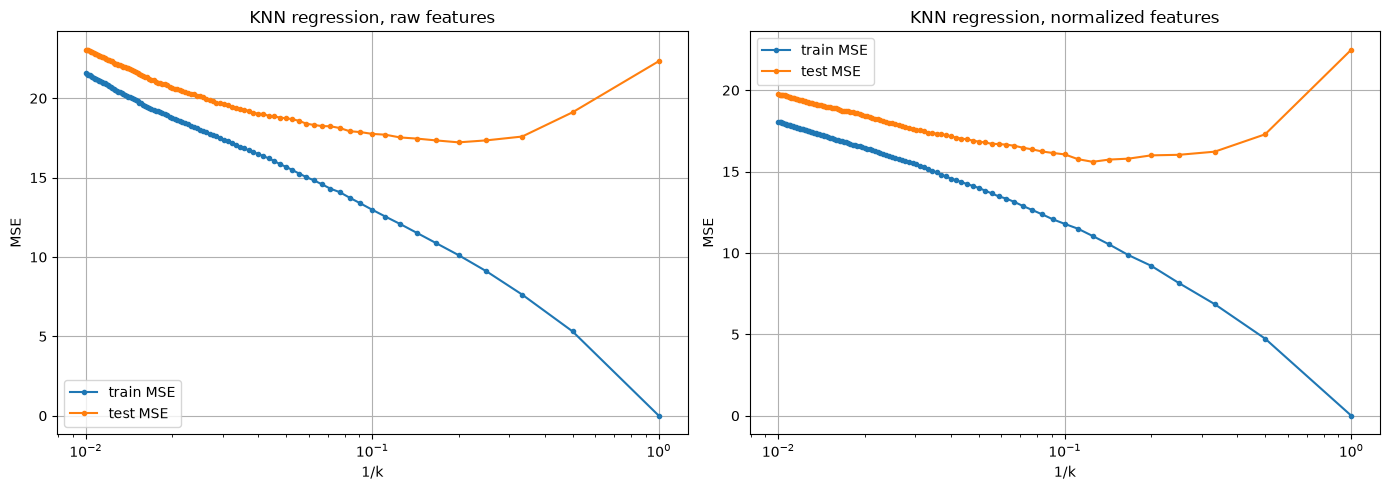

In [13]:
X_train = train[predictors]
X_test = test[predictors]
y_train = train["PE"]
y_test = test["PE"]

scaler = MinMaxScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

k_values = np.arange(1, 101)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name, X_tr, X_te in [(axes[0], "raw", X_train, X_test), (axes[1], "normalized", X_train_norm, X_test_norm)]:
    train_errors = []
    test_errors = []
    for k in k_values:
        knn = KNeighborsRegressor(n_neighbors=k)
        knn.fit(X_tr, y_train)
        train_errors.append(mean_squared_error(y_train, knn.predict(X_tr)))
        test_errors.append(mean_squared_error(y_test, knn.predict(X_te)))

    best = int(np.argmin(test_errors))
    print(name, "features: best k =", k_values[best], " train MSE =", round(train_errors[best], 3),
          " test MSE =", round(test_errors[best], 3))

    ax.plot(1 / k_values, train_errors, marker="o", markersize=3, label="train MSE")
    ax.plot(1 / k_values, test_errors, marker="o", markersize=3, label="test MSE")
    ax.set_xscale("log")
    ax.set_xlabel("1/k")
    ax.set_ylabel("MSE")
    ax.set_title("KNN regression, " + name + " features")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

### (j ) Compare KNN and Linear

The best linear model is the one from (h) with test MSE 19.08. KNN does better: 17.22 with raw features (k = 5) and 15.60 with normalized features (k = 8). There are only 4 features and a lot of data points, so KNN works well here. Normalizing helps because without it the features with bigger ranges, like RH, count more in the distance. The linear model is easier to interpret since it gives a coefficient for each term.

## 2. ISLR: 2.4.1

### (a) The sample size n is extremely large, and the number of predictors p is small.

Better. n is large, so a flexible method can fit the data well without overfitting.

### (b) The number of predictors p is extremely large, and the number of observations n is small.

Worse. n is small and p is large, so a flexible method will overfit.

### (c) The relationship between the predictors and response is highly non-linear.

Better. An inflexible method like linear regression cannot capture a highly non-linear relationship.

### (d) The variance of the error terms, i.e. $\sigma^2 = \text{Var}(\epsilon)$, is extremely high.

Worse. With a lot of noise, a flexible method will end up fitting the noise.

## 3. ISLR: 2.4.7

### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

In [14]:
table = pd.DataFrame({
    "X1": [0, 2, 0, 0, -1, 1],
    "X2": [3, 0, 1, 1, 0, 1],
    "X3": [0, 0, 3, 2, 1, 1],
    "Y": ["Red", "Red", "Red", "Green", "Green", "Red"],
}, index=range(1, 7))
table["distance"] = np.sqrt(table["X1"] ** 2 + table["X2"] ** 2 + table["X3"] ** 2).round(3)
table

,X1,X2,X3,Y,distance
1,0,3,0,Red,3.000
2,2,0,0,Red,2.000
3,0,1,3,Red,3.162
4,0,1,2,Green,2.236
5,-1,0,1,Green,1.414
6,1,1,1,Red,1.732


### (b) What is our prediction with K = 1? Why?

In [15]:
nearest = table.sort_values("distance")
nearest.head(1)

,X1,X2,X3,Y,distance
5,-1,0,1,Green,1.414


Green. The nearest point is observation 5 (distance 1.414), which is Green.

### (c) What is our prediction with K = 3? Why?

In [16]:
nearest.head(3)

,X1,X2,X3,Y,distance
5,-1,0,1,Green,1.414
6,1,1,1,Red,1.732
2,2,0,0,Red,2.000


Red. The 3 nearest points are 5 (Green), 6 (Red) and 2 (Red), so 2 out of 3 are Red.

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

Small. A small K gives a more flexible boundary that can follow a non-linear shape. A large K makes the boundary smoother and closer to linear.